# Hidden riding regimes in NYC Citi Bike: an iterative HMM study

**Team:** Jonathan Sy, Dennis Hantman, Nick Daniel, Maan Patel, Abhinav Sanisetty
**Course:** CSE 150A/250A, Probabilistic Reasoning and Learning

### The question
Every weekday, bikes flow out of residential neighbourhoods in the morning and pile up in job centres, so some stations sit empty while others overflow. The thing that drives this (whether the city is currently *commuting in*, *commuting out*, *riding for leisure*, or *staying home because it's raining*) is never recorded. We only see individual rides. That makes it a natural **latent-variable** problem:

> **Can a Hidden Markov Model recover hidden riding regimes from Citi Bike trip data, and does knowing the current regime help predict the next hour's flow of bikes between residential and job-centre areas?**

### The story of this notebook (three iterations)
| Iteration | Observation per hour | What we learned / why we moved on |
|---|---|---|
| **1. Raw counts** | total rides | States collapse to *busyness levels* (low / medium / high). That's real, but the hour-of-day average already tells you the same thing. |
| **2. Ride composition** | counts of 6 ride *types* (residential→job, job→residential, round trips, ...) | States now differ by *what kind* of riding is happening, not just how much: commute-in, commute-out, leisure. But forecasting still struggles, because a time-homogeneous HMM doesn't know what time it is. |
| **3. Clock-aware HMM** | same 6 counts, with emission rate = (hour-of-week average) × (state multiplier) | The clock explains the routine and the hidden state explains *deviations* from it (rain, holidays, unusually busy days). We implement Baum-Welch for this ourselves. |

Every iteration is compared against two simple baselines: the **hour-of-week average** and **persistence** (next hour = this hour).

### How to run
1. `pip install hmmlearn pandas numpy scipy matplotlib pyarrow`
2. Run top to bottom. The first run downloads ~2 months of trip data (~1 GB of CSVs) and caches a compact version, so later runs are fast.
3. Everything you might want to change lives in the **Config** cell.

In [24]:
import io, json, time, zipfile, urllib.request, warnings, logging
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import gammaln
from hmmlearn import hmm
from hmmlearn.base import ConvergenceMonitor
from sklearn.cluster import KMeans

logging.getLogger("hmmlearn").setLevel(logging.ERROR)   # silence "not converging" chatter; we check convergence ourselves
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 3)

## 0. Config
* **Months**: Sep–Oct 2024. Two busy, "normal" months (school and offices in session, mild weather, a few rainy days, and two Monday holidays: Labor Day on Sep 2 and Indigenous Peoples' Day on Oct 14).
* **Train/test split is by date, never random.** Shuffling hours would leak the future into training, and a time series has to be forecast forward.

In [26]:
MONTHS      = ["202409", "202410"]          # YYYYMM, Citi Bike NYC monthly files
DATA_DIR    = Path("data")
TEST_START  = pd.Timestamp("2024-10-15")    # hours before this = train, from this on = test

AM_HOURS        = [7, 8, 9]   # weekday morning window used to define zones
ZONE_THRESHOLD  = 0.20        # |net inflow share| needed to call a station residential/job
MIN_AM_RIDES    = 40          # stations with fewer AM rides in train are "unclassified"

K_RANGE_HMMLEARN = range(2, 9)   # hidden-state counts to try in iterations 1 & 2
K_RANGE_CLOCK    = range(2, 7)   # ... and in iteration 3
N_RESTARTS       = 5             # EM is sensitive to initialisation, so try several seeds
SEED             = 150
HORIZONS         = range(1, 13)  # forecast 1..12 hours ahead

DATA_DIR.mkdir(exist_ok=True)

## 1. Data sourcing
**Source:** Citi Bike System Data (https://citibikenyc.com/system-data), monthly zips in the public `tripdata` S3 bucket. Each row is one ride: `ride_id, rideable_type, started_at, ended_at, start/end station name + id, start/end lat/lng, member_casual`.

Quirks we handle:
* Some monthly zips contain the month **twice** (as 1M-row chunks *and* as one big file), and some contain **nested zips**. We extract every CSV recursively and then **de-duplicate on `ride_id`**.
* Rides with a missing start or end station are dropped, since they can't be assigned to zones.
* We keep only the columns we need, so two months (~10M rides) fit in memory.

In [27]:
BASE_URL = "https://s3.amazonaws.com/tripdata/{m}-citibike-tripdata.zip"

def _extract_csvs(zf: zipfile.ZipFile, out_dir: Path):
    # Recursively pull every CSV out of a zip (including zips inside the zip).
    for name in zf.namelist():
        if name.startswith("__MACOSX") or name.endswith("/"):
            continue
        if name.lower().endswith(".zip"):
            with zipfile.ZipFile(io.BytesIO(zf.read(name))) as inner:
                _extract_csvs(inner, out_dir)
        elif name.lower().endswith(".csv"):
            target = out_dir / Path(name).name
            if not target.exists():
                target.write_bytes(zf.read(name))

def download_month(m: str) -> Path:
    zip_path, out_dir = DATA_DIR / f"{m}-citibike-tripdata.zip", DATA_DIR / m
    if not zip_path.exists():
        print(f"downloading {BASE_URL.format(m=m)} ...")
        urllib.request.urlretrieve(BASE_URL.format(m=m), zip_path)
    if not out_dir.exists() or not any(out_dir.glob("*.csv")):
        out_dir.mkdir(exist_ok=True)
        with zipfile.ZipFile(zip_path) as zf:
            _extract_csvs(zf, out_dir)
    print(m, "->", sorted(p.name for p in out_dir.glob("*.csv")))
    return out_dir

month_dirs = [download_month(m) for m in MONTHS]

202409 -> ['202409-citibike-tripdata_1.csv', '202409-citibike-tripdata_2.csv', '202409-citibike-tripdata_3.csv', '202409-citibike-tripdata_4.csv', '202409-citibike-tripdata_5.csv']
202410 -> ['202410-citibike-tripdata_1.csv', '202410-citibike-tripdata_2.csv', '202410-citibike-tripdata_3.csv', '202410-citibike-tripdata_4.csv', '202410-citibike-tripdata_5.csv', '202410-citibike-tripdata_6.csv']


In [29]:
try:
    import pyarrow  # noqa: F401
    STR = "string[pyarrow]"     # compact strings: ~5x less memory than Python objects
except ImportError:
    STR = "string"

NEEDED = {"ride_id", "started_at", "start_station_id", "end_station_id", "start_lat", "start_lng", "member_casual"}
RIDES_CACHE, COORDS_CACHE = DATA_DIR / "rides_compact.parquet", DATA_DIR / "station_coords.csv"

def read_trip_csv(path: Path):
    df = pd.read_csv(path, usecols=lambda c: c in NEEDED,
                     dtype={"ride_id": STR, "start_station_id": STR, "end_station_id": STR, "member_casual": STR})
    if not NEEDED.issubset(df.columns):
        print(f"  skipping {path.name}: unexpected columns {list(df.columns)}")
        return None, None
    df = df.dropna(subset=["started_at", "start_station_id", "end_station_id"])
    coords = df.groupby("start_station_id")[["start_lat", "start_lng"]].median()
    out = pd.DataFrame({
        "ride_id": df["ride_id"],
        "hour":    pd.to_datetime(df["started_at"], format="ISO8601").dt.floor("h"),
        "s":       df["start_station_id"],
        "e":       df["end_station_id"],
        "member":  df["member_casual"].eq("member").astype(bool),
    })
    return out, coords

if RIDES_CACHE.exists() and COORDS_CACHE.exists():
    rides = pd.read_parquet(RIDES_CACHE)
    station_coords = pd.read_csv(COORDS_CACHE, index_col=0, dtype={0: str})
    print("loaded cache")
else:
    parts, coord_parts = [], []
    for d in month_dirs:
        for f in sorted(d.glob("*.csv")):
            t0 = time.perf_counter()
            r, c = read_trip_csv(f)
            if r is not None:
                parts.append(r); coord_parts.append(c)
                print(f"  {f.name}: {len(r):,} rides ({time.perf_counter() - t0:.0f}s)")
    rides = pd.concat(parts, ignore_index=True)
    n_raw = len(rides)
    rides = rides.drop_duplicates("ride_id").drop(columns="ride_id").reset_index(drop=True)
    print(f"removed {n_raw - len(rides):,} duplicate rides")
    station_coords = pd.concat(coord_parts).groupby(level=0).median()
    try:
        rides.to_parquet(RIDES_CACHE); station_coords.to_csv(COORDS_CACHE)
    except Exception as ex:
        print("could not cache (install pyarrow for faster reruns):", ex)

PERIOD_START = pd.Timestamp(MONTHS[0] + "01")
PERIOD_END   = (pd.Timestamp(MONTHS[-1] + "01") + pd.offsets.MonthBegin(1))
rides = rides[(rides.hour >= PERIOD_START) & (rides.hour < PERIOD_END)].reset_index(drop=True)
ALL_HOURS = pd.date_range(PERIOD_START, PERIOD_END, freq="h", inclusive="left")
is_test = ALL_HOURS >= TEST_START

print(f"{len(rides):,} rides, {rides.s.nunique():,} start stations, {len(ALL_HOURS)} hours "
      f"({(~is_test).sum()} train / {is_test.sum()} test)")
print(rides.groupby(rides.hour.dt.to_period("M")).size().rename("rides per month"))

loaded cache
10,113,163 rides, 2,240 start stations, 1464 hours (1056 train / 408 test)
hour
2024-09    4980899
2024-10    5132264
Freq: M, Name: rides per month, dtype: int64


**Sanity check.** NYC DOT's monthly operating reports list about **5.01M** rides for Sep 2024 and **5.15M** for Oct 2024. We should land a little below those numbers, because we drop rides with a missing station. If you see roughly double, the de-duplication failed.

## 2. A first look: what does "obvious" structure look like?
Before modelling, we look at the patterns *everyone already knows*: the weekday double peak (8–9am, 5–6pm) and the weekend afternoon hump. Any model we build has to beat "just knowing this".

/var/folders/cz/zcxqr0bn4f3751mpm0ycn0zm0000gn/T/ipykernel_61599/2678070757.py:9: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  how = pd.DataFrame({"rides": total, "wkend": total.index.dayofweek >= 5, "h": total.index.hour})


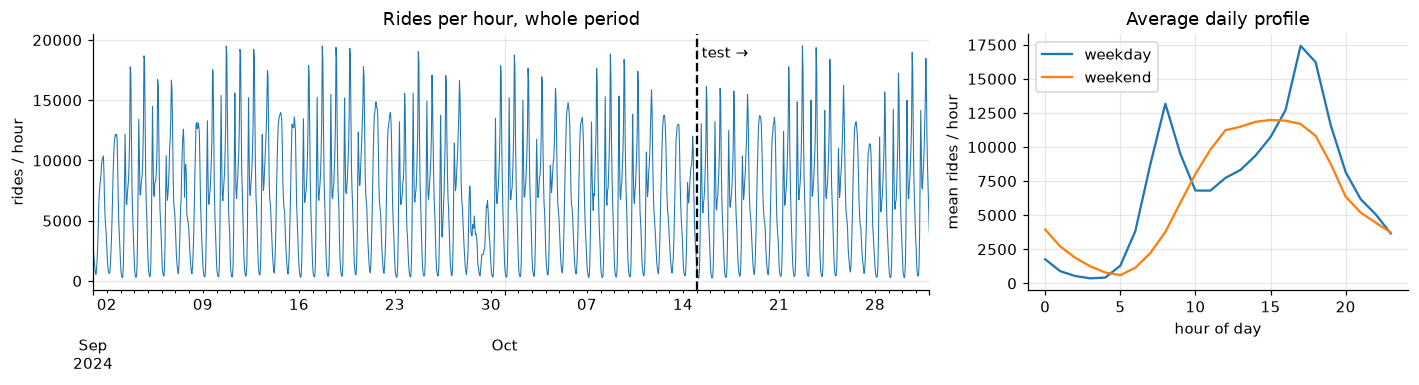

In [30]:
total = rides.groupby("hour").size().reindex(ALL_HOURS, fill_value=0)
members = rides.groupby("hour")["member"].sum().reindex(ALL_HOURS, fill_value=0)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [2.2, 1]})
total.plot(ax=ax[0], lw=0.7)
ax[0].axvline(TEST_START, color="k", ls="--"); ax[0].text(TEST_START, total.max() * 0.95, " test →")
ax[0].set(title="Rides per hour, whole period", ylabel="rides / hour", xlabel="")

how = pd.DataFrame({"rides": total, "wkend": total.index.dayofweek >= 5, "h": total.index.hour})
for wk, g in how.groupby("wkend"):
    ax[1].plot(g.groupby("h").rides.mean(), label="weekend" if wk else "weekday")
ax[1].set(title="Average daily profile", xlabel="hour of day", ylabel="mean rides / hour"); ax[1].legend()
plt.tight_layout(); plt.show()

---
## 3. Iteration 1: an HMM on raw ride counts

### Model
* Hidden state $z_t \in \{1,\dots,K\}$, one per hour, following a first-order Markov chain with start distribution $\pi$ and transition matrix $A_{ij} = P(z_{t+1}=j \mid z_t=i)$.
* Observation $x_t$ = total rides that started in hour $t$, with **Poisson emissions**: $x_t \mid z_t=k \sim \text{Poisson}(\lambda_k)$.

**Why Poisson and not Gaussian?** $x_t$ is a non-negative integer count, and Poisson is the standard distribution for "number of events in a time window". A Gaussian would put probability on negative and fractional ride counts.

### Independence assumptions (we need to state these in the report)
1. **Markov:** $z_{t+1} \perp z_{1:t-1} \mid z_t$. Only the current regime matters for the next one.
2. **Emission:** $x_t \perp$ everything else $\mid z_t$. Given the regime, this hour's count doesn't depend on past counts.
3. **Time-homogeneity:** $A$ is the same at 3am and at 8am. *This assumption is the one that will hurt us.*

### Learning and selection
* **Baum-Welch (EM)** via `hmmlearn.hmm.PoissonHMM`. The E-step runs forward-backward to get $P(z_t \mid x_{1:T})$. The M-step sets $\lambda_k$ to the posterior-weighted mean count and $A$ to the expected transition counts, normalised. EM only finds a *local* optimum, so we run **5 random restarts** and keep the best *training* log-likelihood.
* **Choosing K:** held-out log-likelihood on the test weeks, plus BIC $= -2\log L + p\log T$ with $p = (K-1) + K(K-1) + KF$ free parameters.

### What we expect
The HMM can only "see" how many rides there are, so the states should be **busyness levels**, and their timing should simply mirror the daily profile above.

In [31]:
class FullHistoryMonitor(ConvergenceMonitor):
    # hmmlearn only keeps the last log-likelihoods; we want the whole curve for the convergence plots.
    def _reset(self):
        super()._reset(); self.full_history = []
    def report(self, log_prob):
        if not hasattr(self, "full_history"):
            self.full_history = []
        self.full_history.append(log_prob); super().report(log_prob)

def fit_poisson_hmm(X, K, seed, n_iter=500, tol=1e-2):
    # hmmlearn's default random lambdas can leave a state with zero posterior mass, which turns every
    # parameter into NaN (0/0 in the M-step). Instead, start each state at the mean of a k-means cluster
    # of log-counts, so every state owns some hours; the seed still varies the init across restarts.
    model = hmm.PoissonHMM(n_components=K, n_iter=n_iter, tol=tol, random_state=seed, init_params="st")
    labels = KMeans(K, n_init=1, random_state=seed).fit_predict(np.log1p(X))
    model.lambdas_ = np.array([X[labels == k].mean(axis=0) for k in range(K)]) + 1e-3
    model.monitor_ = FullHistoryMonitor(tol, n_iter, False)
    t0 = time.perf_counter(); model.fit(X); model.fit_seconds_ = time.perf_counter() - t0
    model.history_ = list(model.monitor_.full_history)
    return model

def n_params(K, F):
    return (K - 1) + K * (K - 1) + K * F

def run_sweep(fit_fn, score_fn, Ks, F, T_train, n_restarts=N_RESTARTS, label=""):
    # Fit every K with several seeds; keep, for each K, the restart with the best TRAIN log-likelihood.
    records, best = [], {}
    for K in Ks:
        for r in range(n_restarts):
            m = fit_fn(K, SEED + r)
            tr, te = score_fn(m, "train"), score_fn(m, "test")
            records.append(dict(K=K, restart=r, train_ll=tr, test_ll=te, iters=len(m.history_),
                                seconds=m.fit_seconds_, history=m.history_))
            if K not in best or tr > best[K][1]:
                best[K] = (m, tr)
        print(f"{label} K={K}: best train LL {best[K][1]:,.0f}")
    runs = pd.DataFrame(records)
    summ = (runs.loc[runs.groupby("K").train_ll.idxmax(), ["K", "train_ll", "test_ll", "iters", "seconds"]]
               .set_index("K"))
    summ["BIC"] = -2 * summ.train_ll + np.array([n_params(K, F) for K in summ.index]) * np.log(T_train)
    summ["test_ll_per_hour"] = summ.test_ll / is_test.sum()
    return {K: b[0] for K, b in best.items()}, runs, summ

def choose_K(summ, frac=0.9):
    # Smallest K that captures `frac` of the total held-out log-likelihood gain (an 'elbow' rule).
    gain = summ.test_ll - summ.test_ll.iloc[0]
    if gain.max() <= 0:
        return summ.index[0]
    return int(gain.index[gain >= frac * gain.max()][0])

def plot_sweep(summ, runs, title):
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
    ax[0].plot(summ.index, summ.test_ll_per_hour, "o-"); ax[0].set(title="Held-out log-lik per test hour", xlabel="K")
    ax[1].plot(summ.index, summ.BIC, "o-", color="C1"); ax[1].set(title="BIC on train (lower = better)", xlabel="K")
    for K, g in runs.groupby("K"):
        ax[2].scatter(np.full(len(g), K), g.train_ll - g.train_ll.max(), alpha=0.7)
    ax[2].set(title="Restarts: train LL minus best restart", xlabel="K", ylabel="Δ log-lik")
    fig.suptitle(title); plt.tight_layout(); plt.show()

iter1 K=2: best train LL -587,776
iter1 K=3: best train LL -272,708
iter1 K=4: best train LL -151,606
iter1 K=5: best train LL -117,386
iter1 K=6: best train LL -77,786
iter1 K=7: best train LL -53,052
iter1 K=8: best train LL -42,188


,test_ll,iters,seconds,BIC,test_ll_per_hour
K,,,,,
2,-226445.770,8,0.004,1.176e+06,-555.014
3,-108442.123,18,0.011,5.455e+05,-265.790
4,-60736.701,23,0.013,3.033e+05,-148.864
5,-48708.439,20,0.013,2.350e+05,-119.383
6,-31623.977,28,0.025,1.559e+05,-77.510
7,-24186.527,29,0.042,1.065e+05,-59.281
8,-19349.410,13,0.018,8.487e+04,-47.425


BIC-optimal K: 8 | elbow-chosen K: 6


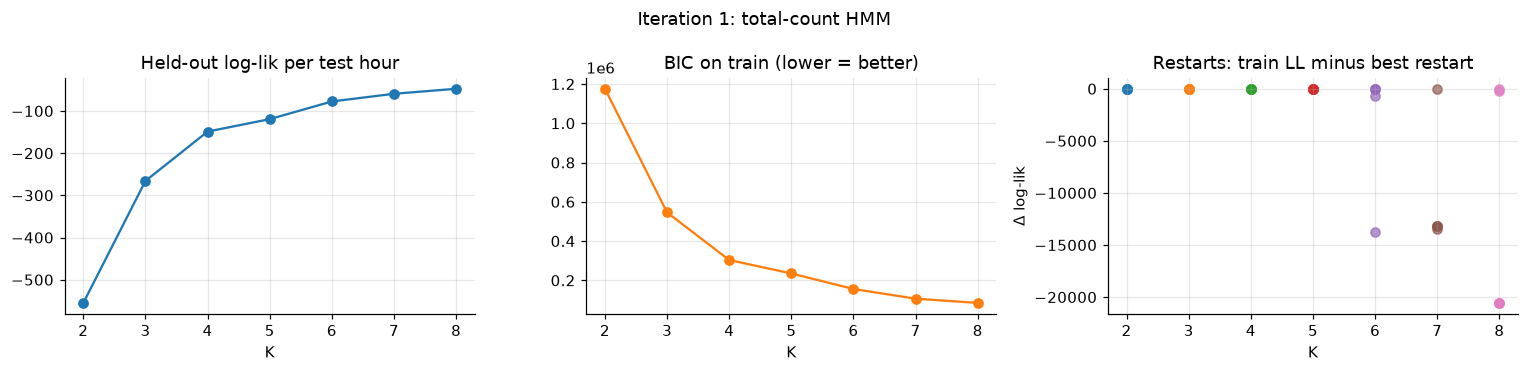

In [32]:
X1 = total.to_numpy().reshape(-1, 1).astype(int)          # (T, 1)
X1_tr, X1_te = X1[~is_test], X1[is_test]

models1, runs1, summ1 = run_sweep(
    fit_fn=lambda K, s: fit_poisson_hmm(X1_tr, K, s),
    score_fn=lambda m, part: m.score(X1_tr if part == "train" else X1_te),
    Ks=K_RANGE_HMMLEARN, F=1, T_train=len(X1_tr), label="iter1")
K1 = choose_K(summ1)
display(summ1.drop(columns=["train_ll"]))
print("BIC-optimal K:", summ1.BIC.idxmin(), "| elbow-chosen K:", K1)
plot_sweep(summ1, runs1, "Iteration 1: total-count HMM")

**How to read this.** With counts in the hundreds or thousands per hour, real data is far *more variable* than a single Poisson allows (overdispersion: a Poisson's variance equals its mean). The model compensates by adding states that cut the count range into finer slices, so BIC and held-out likelihood often keep improving as K grows. That is itself a finding: *more states ≠ more meaning*. We pick K with the elbow rule and then check whether the states mean anything.

Emission rates λ_k (sorted): [  574.1  1678.3  4026.7  7091.9 10229.2 14833.9]


/var/folders/cz/zcxqr0bn4f3751mpm0ycn0zm0000gn/T/ipykernel_61599/1466872155.py:7: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  df = pd.DataFrame({"z": states, "h": ALL_HOURS.hour, "wk": ALL_HOURS.dayofweek >= 5})


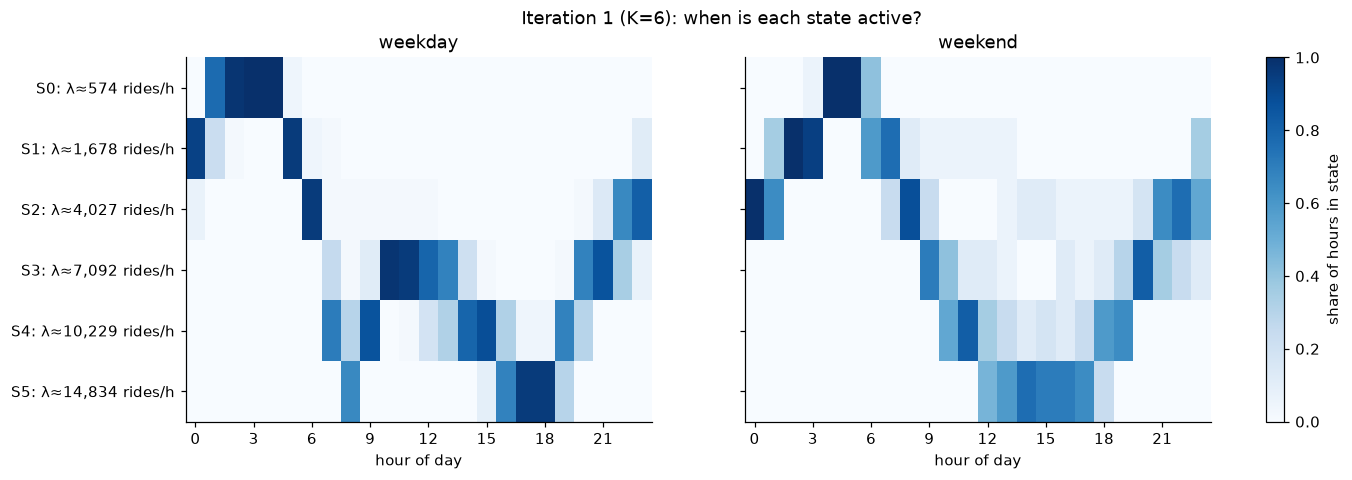

In [33]:
def relabel_by(values):
    # Return a mapping old_state -> new_state so that new labels are sorted by `values` (ascending).
    order = np.argsort(values); rank = np.empty_like(order); rank[order] = np.arange(len(order)); return rank

def occupancy_heatmap(states, K, title, names=None):
    # Fraction of hours of each hour-of-day assigned to each state, weekday vs weekend.
    df = pd.DataFrame({"z": states, "h": ALL_HOURS.hour, "wk": ALL_HOURS.dayofweek >= 5})
    fig, axes = plt.subplots(1, 2, figsize=(13, 0.45 * K + 1.6), sharey=True)
    for ax, (wk, g) in zip(axes, df.groupby("wk")):
        occ = pd.crosstab(g.z, g.h, normalize="columns").reindex(range(K), fill_value=0)
        im = ax.imshow(occ, aspect="auto", cmap="Blues", vmin=0, vmax=1)
        ax.set(title=("weekend" if wk else "weekday"), xlabel="hour of day", xticks=range(0, 24, 3))
        ax.grid(False)
    axes[0].set_yticks(range(K), names if names is not None else [f"state {k}" for k in range(K)])
    fig.colorbar(im, ax=axes, label="share of hours in state", fraction=0.025)
    fig.suptitle(title); plt.show()

m1 = models1[K1]
rank1 = relabel_by(m1.lambdas_[:, 0])
z1 = rank1[m1.predict(X1)]                         # Viterbi path over the whole period
lam1 = np.sort(m1.lambdas_[:, 0])
names1 = [f"S{k}: λ≈{l:,.0f} rides/h" for k, l in enumerate(lam1)]
print("Emission rates λ_k (sorted):", np.round(lam1, 1))
occupancy_heatmap(z1, K1, f"Iteration 1 (K={K1}): when is each state active?", names1)

**What we expect to see.** The heatmap is basically the daily profile again: the highest-λ state lights up at 8am and 5–6pm on weekdays, the lowest at night. The states are **busyness levels**. They are real, but they tell Lyft nothing that a table of hourly averages doesn't. This motivates Iteration 2: *change what we observe, not just how many states we use.*

---
## 4. Iteration 2: from "how much" to "what kind" of riding

### Defining zones from the data (training period only)
For rebalancing, the important thing is the **direction** of flow. We label each station by its weekday-morning (7–10am) behaviour in the **training weeks**:

$$\text{net share}_s = \frac{\text{arrivals}_s - \text{departures}_s}{\text{arrivals}_s + \text{departures}_s}$$

* **J (job centre):** net share ≥ +0.15, so bikes pile up here in the morning
* **R (residential):** net share ≤ −0.15, so bikes drain from here in the morning
* **M (mixed):** in between. **U (unclassified):** fewer than 40 morning rides.

We use only training data so that the test period stays unseen. *Caveat for the report:* zones are defined from morning behaviour, so "R→J is high in the morning" is partly true **by construction**. What the HMM has to discover on its own is *when* each kind of riding dominates, without being told the clock.

/var/folders/cz/zcxqr0bn4f3751mpm0ycn0zm0000gn/T/ipykernel_61599/2189251894.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  am = train_rides[(train_rides.hour.dt.dayofweek < 5) & train_rides.hour.dt.hour.isin(AM_HOURS)]


zone
R    894
M    745
J    474
U    132
Name: stations per zone, dtype: int64


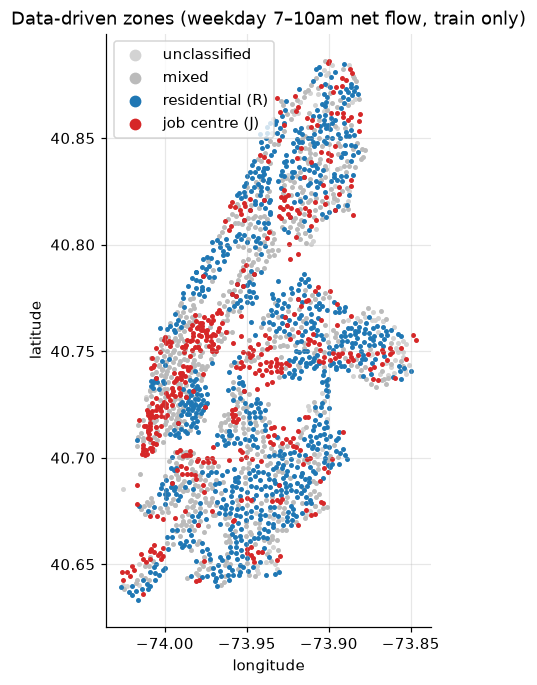

In [34]:
train_rides = rides[rides.hour < TEST_START]
am = train_rides[(train_rides.hour.dt.dayofweek < 5) & train_rides.hour.dt.hour.isin(AM_HOURS)]
st = pd.concat([am.groupby("s").size().rename("dep"), am.groupby("e").size().rename("arr")], axis=1).fillna(0)
st["n"] = st.dep + st.arr
st["net_share"] = (st.arr - st.dep) / st.n
st["zone"] = np.select([st.n < MIN_AM_RIDES, st.net_share >= ZONE_THRESHOLD, st.net_share <= -ZONE_THRESHOLD],
                       ["U", "J", "R"], default="M")
zone_of = st.zone.to_dict()
print(st.zone.value_counts().rename("stations per zone"))

coords = station_coords.join(st.zone, how="inner")
fig, ax = plt.subplots(figsize=(6, 7))
for z, c in [("U", "lightgrey"), ("M", "#bbbbbb"), ("R", "C0"), ("J", "C3")]:
    g = coords[coords.zone == z]
    ax.scatter(g.start_lng, g.start_lat, s=5, c=c, label={"R": "residential (R)", "J": "job centre (J)", "M": "mixed", "U": "unclassified"}[z])
ax.set(title="Data-driven zones (weekday 7–10am net flow, train only)", xlabel="longitude", ylabel="latitude"); ax.legend(markerscale=3)
ax.set_aspect(1.3); plt.show()

**What we expect.** Midtown, the Financial District and other office areas show up as **J**, while the Upper East/West Side, Harlem and much of Brooklyn and Queens show up as **R**. If the map looks like NYC's commuting geography, the zone definition is credible. That's a nice qualitative check for the report.

### Ride types (the new observation vector)
Every ride gets exactly one type, checked in this order:
1. `round_trip`: start station = end station (a strong leisure signal)
2. `R_to_J`, `J_to_R`: the commuting directions
3. `within_R`, `within_J`: local trips
4. `other`: anything touching a mixed or unclassified station

Because the types are exhaustive, the six counts always sum to the Iteration 1 total. **Member/casual is deliberately NOT an input.** We hold it out and use it afterwards to *validate* what the states mean. (We also never feed in a "commuter" label, because that would hand the model the answer.)

type
R_to_J        0.069
J_to_R        0.062
within_R      0.104
within_J      0.053
round_trip    0.020
other         0.692
Name: share of all rides, dtype: float64


/var/folders/cz/zcxqr0bn4f3751mpm0ycn0zm0000gn/T/ipykernel_61599/4172816631.py:14: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  wk = counts[counts.index.dayofweek < 5]


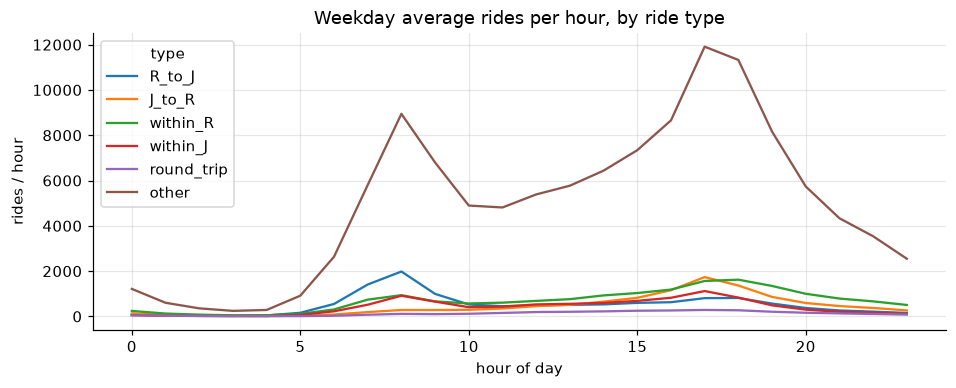

In [35]:
FEATURES = ["R_to_J", "J_to_R", "within_R", "within_J", "round_trip", "other"]
zs = rides.s.map(zone_of).fillna("U").to_numpy(dtype=object)
ze = rides.e.map(zone_of).fillna("U").to_numpy(dtype=object)
same = (rides.s == rides.e).to_numpy(dtype=bool)
rides["type"] = pd.Categorical(np.select(
    [same, (zs == "R") & (ze == "J"), (zs == "J") & (ze == "R"), (zs == "R") & (ze == "R"), (zs == "J") & (ze == "J")],
    ["round_trip", "R_to_J", "J_to_R", "within_R", "within_J"], default="other"), categories=FEATURES)

counts = (rides.groupby(["hour", "type"], observed=False).size().unstack(fill_value=0)
               .reindex(index=ALL_HOURS, columns=FEATURES, fill_value=0))
assert (counts.sum(axis=1).to_numpy() == total.to_numpy()).all()
print((counts.sum() / counts.to_numpy().sum()).rename("share of all rides").round(3))

wk = counts[counts.index.dayofweek < 5]
prof = wk.groupby(wk.index.hour).mean()
prof.plot(figsize=(10, 3.5), title="Weekday average rides per hour, by ride type")
plt.xlabel("hour of day"); plt.ylabel("rides / hour"); plt.show()

### Iteration 2 model
Same HMM, but now $x_t \in \mathbb{N}^6$ with **independent Poisson emissions per ride type given the state**:
$$P(x_t \mid z_t=k) = \prod_{f=1}^{6} \text{Poisson}(x_{tf};\, \lambda_{kf}).$$
Each state now has a *fingerprint*: how much of each kind of riding it produces. The new independence assumption is that **the six counts are independent given the regime**. This is plausible because the regime is what couples them (rush hour raises R→J *and* within_J). But leftover correlation, e.g. from weather, would violate it.

**Why counts instead of shares (percentages)?** Shares are meaningless at 3am when there are only 4 rides. They also sum to 1, which makes a full-covariance Gaussian degenerate. Counts keep *both* volume and composition, and the Poisson naturally treats quiet hours as noisy.

iter2 K=2: best train LL -728,911
iter2 K=3: best train LL -413,253
iter2 K=4: best train LL -286,990
iter2 K=5: best train LL -249,920
iter2 K=6: best train LL -204,365
iter2 K=7: best train LL -161,214
iter2 K=8: best train LL -150,764


,test_ll,iters,seconds,BIC,test_ll_per_hour
K,,,,,
2,-283905.472,7,0.005,1.458e+06,-695.847
3,-165391.617,19,0.013,8.267e+05,-405.372
4,-115274.872,30,0.034,5.743e+05,-282.536
5,-104139.296,18,0.019,5.002e+05,-255.243
6,-84566.557,23,0.031,4.092e+05,-207.271
7,-67575.724,48,0.092,3.231e+05,-165.627
8,-63079.070,45,0.094,3.023e+05,-154.606


BIC-optimal K: 8 | elbow-chosen K: 6


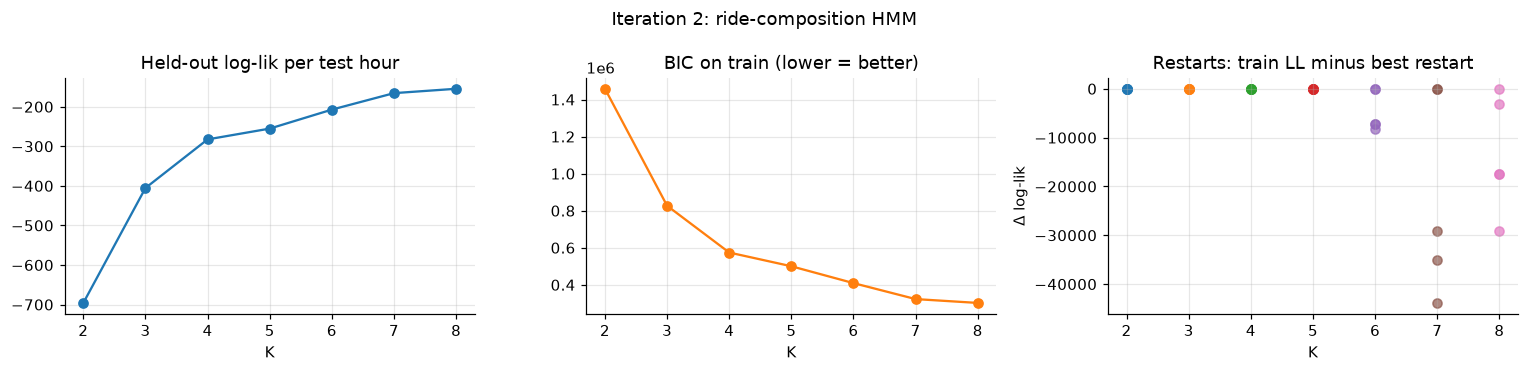

In [36]:
X2 = counts.to_numpy().astype(int)        # (T, 6)
X2_tr, X2_te = X2[~is_test], X2[is_test]

models2, runs2, summ2 = run_sweep(
    fit_fn=lambda K, s: fit_poisson_hmm(X2_tr, K, s),
    score_fn=lambda m, part: m.score(X2_tr if part == "train" else X2_te),
    Ks=K_RANGE_HMMLEARN, F=len(FEATURES), T_train=len(X2_tr), label="iter2")
K2 = choose_K(summ2)
display(summ2.drop(columns=["train_ll"]))
print("BIC-optimal K:", summ2.BIC.idxmin(), "| elbow-chosen K:", K2)
plot_sweep(summ2, runs2, "Iteration 2: ride-composition HMM")

,R_to_J,J_to_R,within_R,within_J,round_trip,other,total rides/h,member share (held out)
"S0: 577/h, most over-rep: round_trip",0.93,0.96,1.34,0.70,1.61,0.96,577.32,0.73
"S1: 1,839/h, most over-rep: within_R",0.98,0.92,1.26,0.66,1.18,0.99,1838.91,0.76
"S2: 4,549/h, most over-rep: within_R",0.95,0.95,1.21,0.71,1.07,1.00,4549.29,0.79
"S3: 8,119/h, most over-rep: round_trip",0.92,0.95,0.99,1.02,1.13,1.01,8119.15,0.80
"S4: 11,338/h, most over-rep: R_to_J",2.08,0.37,0.70,1.27,0.44,0.99,11338.08,0.89
"S5: 13,951/h, most over-rep: J_to_R",0.77,1.22,1.01,0.99,1.08,1.00,13951.41,0.79


/var/folders/cz/zcxqr0bn4f3751mpm0ycn0zm0000gn/T/ipykernel_61599/1466872155.py:7: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  df = pd.DataFrame({"z": states, "h": ALL_HOURS.hour, "wk": ALL_HOURS.dayofweek >= 5})


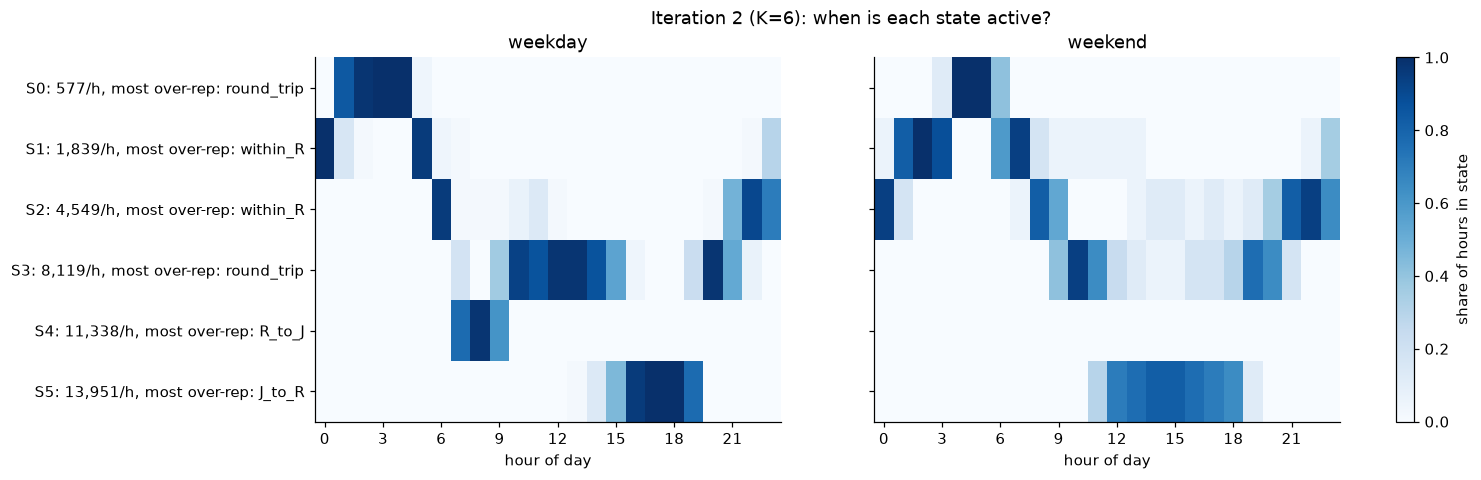

In [38]:
m2 = models2[K2]
lam2 = m2.lambdas_                                          # (K, 6)
rank2 = relabel_by(lam2.sum(1))
lam2 = lam2[np.argsort(lam2.sum(1))]
z2 = rank2[m2.predict(X2)]

share = lam2 / lam2.sum(1, keepdims=True)
overall = X2.sum(0) / X2.sum()
lift = share / overall                                      # >1 = over-represented in this state
member_share = pd.Series(members.to_numpy()).groupby(z2).sum() / pd.Series(total.to_numpy()).groupby(z2).sum()

def auto_name(k):
    top = FEATURES[int(np.argmax(lift[k]))]
    return f"S{k}: {lam2[k].sum():,.0f}/h, most over-rep: {top}"
names2 = [auto_name(k) for k in range(K2)]

fp = pd.DataFrame(lift, columns=FEATURES, index=names2)
fp["total rides/h"] = lam2.sum(1); fp["member share (held out)"] = member_share.reindex(range(K2)).to_numpy()
display(fp.style.background_gradient(cmap="RdBu_r", subset=FEATURES, vmin=0, vmax=2).format("{:.2f}"))
occupancy_heatmap(z2, K2, f"Iteration 2 (K={K2}): when is each state active?", names2)

**How to read the fingerprint table.** Each cell is the *lift*: a ride type's share inside the state divided by its overall share. A value of 2.0 means "twice as common as usual". What we expect:
* a state with high **R_to_J** lift that lives at weekday 7–10am → **commute in**
* a state with high **J_to_R** lift at weekday 4–7pm → **commute out**
* a state with high **round_trip / within_R** lift on weekend afternoons → **leisure**
* a low-volume night state

The **member share** column was never shown to the model. If the commute states have a noticeably higher member share than the leisure state, that's *independent evidence* the states mean what we say they mean. Name the states yourselves based on this table, and say in the report *why* you named them that.

### Iteration 1 vs 2 in one picture
Each dot is an hour, plotted by volume (x) and **directional balance** (y) = (R→J − J→R)/(R→J + J→R). Iteration 1 states can only separate hours along x. If Iteration 2 states also separate along y, the model has learned *direction*, which is the thing rebalancing needs.

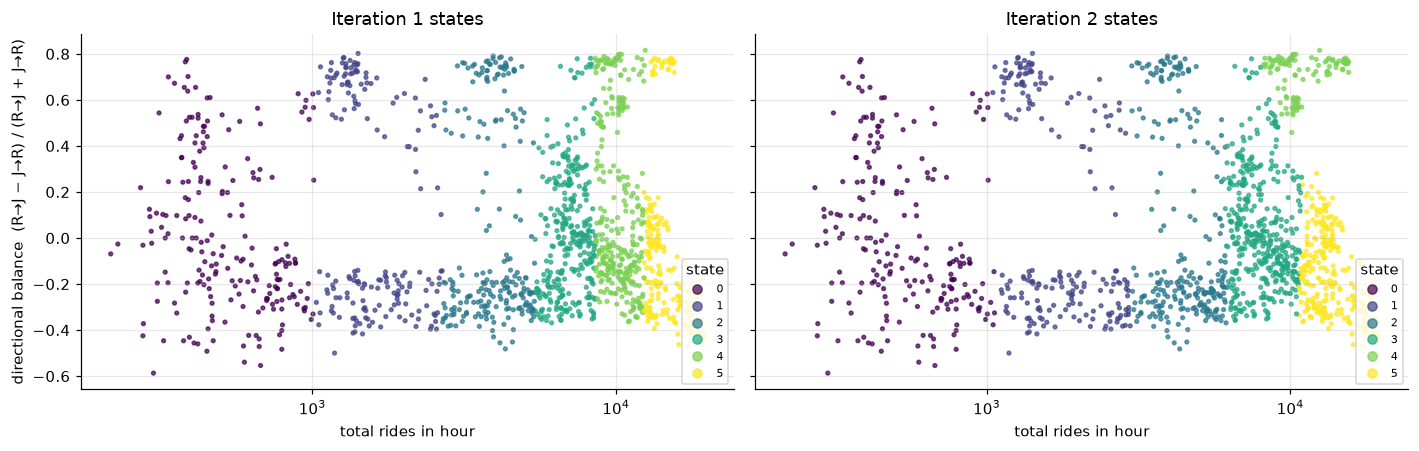

In [39]:
bal = (counts.R_to_J - counts.J_to_R) / (counts.R_to_J + counts.J_to_R + 1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for a, z, K, t in [(ax[0], z1, K1, "Iteration 1 states"), (ax[1], z2, K2, "Iteration 2 states")]:
    sc = a.scatter(total, bal, c=z, cmap="viridis", s=6, alpha=0.7, vmin=0, vmax=K - 1)
    a.set(title=t, xlabel="total rides in hour"); a.set_xscale("symlog")
    a.legend(*sc.legend_elements(), title="state", fontsize=7, loc="lower right")
ax[0].set_ylabel("directional balance  (R→J − J→R) / (R→J + J→R)")
plt.tight_layout(); plt.show()

---
## 5. Inference by hand: forward filtering and Viterbi
To forecast, we need **filtering**, $P(z_t \mid x_{1:t})$, which uses only the past. `hmmlearn.predict_proba` returns *smoothed* posteriors $P(z_t \mid x_{1:T})$, which use the future and would be cheating for forecasting. So we implement the **forward algorithm** ourselves:

$$\alpha_1(k) \propto \pi_k\, p(x_1 \mid k), \qquad \alpha_t(k) \propto \Big[\sum_j \alpha_{t-1}(j) A_{jk}\Big]\, p(x_t \mid k)$$

We normalise $\alpha_t$ at every step (scaling) to avoid numerical underflow. The log of the normalisers summed over time is exactly $\log P(x_{1:T})$, which lets us **verify our implementation** against `hmmlearn.score`.

**Forecasting h hours ahead:** $P(z_{t+h} \mid x_{1:t}) = \alpha_t A^h$, and $\mathbb{E}[x_{t+h} \mid x_{1:t}] = \sum_k P(z_{t+h}=k \mid x_{1:t})\, \lambda_k$. As $h$ grows, $\alpha_t A^h$ converges to the stationary distribution of $A$, so long-range forecasts flatten toward a constant. That is another reason the clock-blind HMM struggles.

**Viterbi** (max-product instead of sum-product) gives the single most likely state *path*. We implement it too and check it against `hmmlearn.decode`.

In [ ]:
def poisson_log_emissions(X, lam):
    # log p(x_t | z_t=k) for independent Poisson features. X: (T,F), lam: (K,F) or (T,K,F) -> (T,K)
    lam = np.maximum(lam, 1e-10)
    if lam.ndim == 2:
        lam = lam[None]
    return (X[:, None, :] * np.log(lam) - lam - gammaln(X + 1)[:, None, :]).sum(-1)

def forward_filter(logB, startprob, transmat):
    # Scaled forward algorithm. Returns filt[t] = P(z_t | x_1..t) and log P(x_1..T).
    T, K = logB.shape
    filt, loglik, prior = np.empty((T, K)), 0.0, startprob
    for t in range(T):
        lw = np.log(prior + 1e-300) + logB[t]
        mx = lw.max(); w = np.exp(lw - mx); s = w.sum()
        filt[t] = w / s
        loglik += mx + np.log(s)
        prior = filt[t] @ transmat
    return filt, loglik

def viterbi(logB, startprob, transmat):
    T, K = logB.shape
    logA = np.log(transmat + 1e-300)
    delta = np.log(startprob + 1e-300) + logB[0]; back = np.zeros((T, K), dtype=int)
    for t in range(1, T):
        cand = delta[:, None] + logA                 # (from, to)
        back[t] = cand.argmax(0); delta = cand.max(0) + logB[t]
    path = np.empty(T, dtype=int); path[-1] = delta.argmax()
    for t in range(T - 1, 0, -1):
        path[t - 1] = back[t, path[t]]
    return path

# --- verify our implementations against hmmlearn on the Iteration 2 model
logB2 = poisson_log_emissions(X2.astype(float), m2.lambdas_)
filt2, ll_ours = forward_filter(logB2, m2.startprob_, m2.transmat_)
print(f"log P(x) ours = {ll_ours:,.3f}   hmmlearn = {m2.score(X2):,.3f}")
assert np.isclose(ll_ours, m2.score(X2), rtol=1e-6)
agree = (viterbi(logB2, m2.startprob_, m2.transmat_) == m2.predict(X2)).mean()
print(f"Viterbi path agreement with hmmlearn: {agree:.1%}")

## 6. Does knowing the regime help forecasting? (Iterations 1 & 2 vs baselines)
**Targets on the test weeks:**
* total rides next hour
* `R_to_J` and `J_to_R` next hour
* **net flow into job centres** = R_to_J − J_to_R. This is the quantity that empties residential docks, so it's the one rebalancing acts on.

**Methods:**
* **Hour-of-week mean:** average of the train weeks for the same weekday and hour. Knows the clock, ignores the present.
* **Persistence:** next hour = this hour. Knows the present, ignores the clock.
* **HMM (iter 1 / iter 2):** forward-filter on everything up to $t-h$, propagate $h$ steps, then take the expected emission.

**Metric:** mean absolute error (MAE), in rides per hour.

**What we expect.** Both clock-blind HMMs will probably **lose to the hour-of-week mean beyond 1–2 hours**. Their only idea of "8am is coming" is the transition matrix, and $A^h$ washes out quickly. At $h=1$ they behave like a smoothed persistence. *This is not a failure to hide.* It is the key diagnostic that motivates Iteration 3.

In [ ]:
how_key = lambda idx: idx.dayofweek * 24 + idx.hour
train_counts = counts[~is_test]
how_means = train_counts.groupby(how_key(train_counts.index)).mean()
B_how = how_means.reindex(how_key(ALL_HOURS)).to_numpy()          # (T, 6) clock baseline for every hour

def targets(F6):
    # Map a (T,6) array of ride-type forecasts/actuals to the evaluation targets.
    F6 = np.asarray(F6, float)
    return {"total": F6.sum(1), "R_to_J": F6[:, 0], "J_to_R": F6[:, 1], "net_into_J": F6[:, 0] - F6[:, 1]}

def hmm_forecast(filt, transmat, rate_fn, h):
    P = np.full_like(filt, np.nan)
    P[h:] = filt[:-h] @ np.linalg.matrix_power(transmat, h)     # P(z_t | x_1..t-h)
    return rate_fn(P)

def persistence(X, h):
    out = np.full(X.shape, np.nan); out[h:] = X[:-h]; return out

filt1, _ = forward_filter(poisson_log_emissions(X1.astype(float), m1.lambdas_), m1.startprob_, m1.transmat_)
actual = targets(X2)

def evaluate(forecasters, horizons):
    rows = []
    for h in horizons:
        for name, fn in forecasters.items():
            pred = fn(h)
            for tgt, y in actual.items():
                if tgt in pred:
                    rows.append(dict(h=h, method=name, target=tgt, MAE=np.nanmean(np.abs(pred[tgt][is_test] - y[is_test]))))
    return pd.DataFrame(rows)

forecasters = {
    "hour-of-week mean": lambda h: targets(B_how),
    "persistence":       lambda h: targets(persistence(X2, h)),
    "HMM iter1 (counts)": lambda h: {"total": hmm_forecast(filt1, m1.transmat_, lambda P: P @ m1.lambdas_, h)[:, 0]},
    "HMM iter2 (composition)": lambda h: targets(hmm_forecast(filt2, m2.transmat_, lambda P: P @ m2.lambdas_, h)),
}
res12 = evaluate(forecasters, HORIZONS)
display(res12[res12.h == 1].pivot(index="method", columns="target", values="MAE")[list(actual)].round(1))

---
## 7. Iteration 3: a clock-aware HMM (our own Baum-Welch)

### The diagnosis
Iteration 2's states are mostly *time-of-day in disguise*. The HMM spends its states re-learning the daily cycle that the calendar already gives us for free. What the calendar **can't** tell us is whether *today* is unusual: rain, a holiday, a heat wave, an event. That deviation is the truly hidden part.

### The model
Keep the 6 ride-type counts, and let the hidden state act as a **multiplier on the clock baseline** $b_{tf}$ (the hour-of-week mean from training):
$$x_{tf} \mid z_t = k \;\sim\; \text{Poisson}(b_{tf}\, m_{kf})$$
* $m_{kf}=1$: riding is normal for this time of week
* $m_{kf}=0.5$: half the usual riding of type $f$ (rain?)
* low $m$ for R_to_J but high for round_trip: a weekday that behaves like a weekend (holiday?)

The Markov chain over $z_t$ captures that unusual conditions **persist** for several hours (a rainy afternoon, a holiday all day). The independence assumptions are unchanged, except that the emission now depends on the known clock $b_t$ as well as on $z_t$.

### Learning it: Baum-Welch derived for this model
`hmmlearn` can't express "rate = known baseline × state multiplier", so we implement EM ourselves:
* **E-step:** scaled forward-backward gives $\gamma_t(k) = P(z_t=k \mid x_{1:T})$ and the expected transition counts $\sum_t \xi_t(j,k)$.
* **M-step:** $\pi = \gamma_1$, and $A_{jk} \propto \sum_t \xi_t(j,k)$. Setting the derivative of the expected complete-data log-likelihood with respect to $m_{kf}$ to zero gives a closed form:
$$m_{kf} = \frac{\sum_t \gamma_t(k)\, x_{tf}}{\sum_t \gamma_t(k)\, b_{tf}}$$
i.e. "observed rides ÷ expected rides", weighted by how much each hour belongs to state $k$.

EM guarantees the log-likelihood **never decreases**, so we assert this as a correctness check on our implementation.

In [ ]:
class ClockAwarePoissonHMM:
    # x_tf | z_t=k ~ Poisson(B_tf * m_kf), with z_t a first-order Markov chain. Fit by Baum-Welch (EM).

    def __init__(self, n_components, n_iter=300, tol=1e-2, random_state=0):
        self.K, self.n_iter, self.tol, self.random_state = n_components, n_iter, tol, random_state

    def _init(self, X, B):
        rng = np.random.default_rng(self.random_state)
        K, F = self.K, X.shape[1]
        ratio = X.sum(1) / B.sum(1)
        levels = np.quantile(ratio, (np.arange(K) + 0.5) / K)          # spread initial multipliers over observed ratios
        self.multipliers_ = levels[:, None] * rng.uniform(0.85, 1.15, (K, F))
        self.startprob_ = np.full(K, 1 / K)
        A = rng.uniform(0.5, 1.5, (K, K)) + 5 * K * np.eye(K)          # sticky start: regimes persist
        self.transmat_ = A / A.sum(1, keepdims=True)

    def log_emissions(self, X, B):
        return poisson_log_emissions(X, B[:, None, :] * self.multipliers_[None, :, :])

    def _forward_backward(self, logB):
        T, K = logB.shape; A = self.transmat_
        mx = logB.max(1, keepdims=True); b = np.exp(logB - mx)        # per-row rescaling for numerical stability
        alpha, c = np.empty((T, K)), np.empty(T)
        alpha[0] = self.startprob_ * b[0]; c[0] = alpha[0].sum(); alpha[0] /= c[0]
        for t in range(1, T):
            alpha[t] = (alpha[t - 1] @ A) * b[t]; c[t] = alpha[t].sum(); alpha[t] /= c[t]
        beta = np.ones((T, K))
        for t in range(T - 2, -1, -1):
            beta[t] = A @ (b[t + 1] * beta[t + 1]) / c[t + 1]
        gamma = alpha * beta; gamma /= gamma.sum(1, keepdims=True)
        xi_sum = A * (alpha[:-1].T @ (b[1:] * beta[1:] / c[1:, None]))
        return gamma, xi_sum, np.log(c).sum() + mx.sum()

    def fit(self, X, B):
        X, B = np.asarray(X, float), np.maximum(np.asarray(B, float), 1e-3)
        self._init(X, B); self.history_ = []
        t0 = time.perf_counter()
        for it in range(self.n_iter):
            gamma, xi_sum, ll = self._forward_backward(self.log_emissions(X, B))
            self.history_.append(ll)
            if it > 0 and ll - self.history_[-2] < self.tol:
                break
            # ---- M-step (closed form)
            self.startprob_ = (gamma[0] + 1e-6) / (gamma[0] + 1e-6).sum()
            self.transmat_ = (xi_sum + 1e-6) / (xi_sum + 1e-6).sum(1, keepdims=True)
            self.multipliers_ = np.maximum((gamma.T @ X) / (gamma.T @ B), 1e-6)
        self.fit_seconds_ = time.perf_counter() - t0
        h = np.array(self.history_)
        assert np.all(np.diff(h) >= -1e-6 * np.abs(h[:-1])), "EM log-likelihood decreased: bug!"
        return self

    def score(self, X, B):
        return forward_filter(self.log_emissions(np.asarray(X, float), np.maximum(B, 1e-3)), self.startprob_, self.transmat_)[1]

    def filter(self, X, B):
        return forward_filter(self.log_emissions(np.asarray(X, float), np.maximum(B, 1e-3)), self.startprob_, self.transmat_)[0]

    def decode(self, X, B):
        return viterbi(self.log_emissions(np.asarray(X, float), np.maximum(B, 1e-3)), self.startprob_, self.transmat_)

**Sanity check of our EM.** If the baseline is set to all ones, $b_{tf}=1$, the model reduces to an ordinary Poisson HMM with $\lambda_{kf}=m_{kf}$. Our implementation should then reach about the same log-likelihood as `hmmlearn` on the same data. It may differ slightly, since different initialisations can land in different local optima.

In [ ]:
ones = np.ones_like(X2_tr, dtype=float)
ours = max((ClockAwarePoissonHMM(K2, random_state=SEED + r).fit(X2_tr, ones) for r in range(N_RESTARTS)), key=lambda m: m.history_[-1])
print(f"K={K2}, baseline=1   our EM: {ours.score(X2_tr, ones):,.1f}   hmmlearn: {models2[K2].score(X2_tr):,.1f}")

In [ ]:
B_tr, B_te = B_how[~is_test], B_how[is_test]
models3, runs3, summ3 = run_sweep(
    fit_fn=lambda K, s: ClockAwarePoissonHMM(K, random_state=s).fit(X2_tr, B_tr),
    score_fn=lambda m, part: m.score(X2_tr, B_tr) if part == "train" else m.score(X2_te, B_te),
    Ks=K_RANGE_CLOCK, F=len(FEATURES), T_train=len(X2_tr), label="iter3")
K3 = choose_K(summ3)
display(summ3.drop(columns=["train_ll"]))
print("BIC-optimal K:", summ3.BIC.idxmin(), "| elbow-chosen K:", K3)
plot_sweep(summ3, runs3, "Iteration 3: clock-aware HMM")

# Also useful for the report: how much does the clock alone explain? (log-lik of the K=1 'model' = baseline only)
base_te = poisson_log_emissions(X2_te.astype(float), np.maximum(B_te, 1e-3)[:, None, :])[:, 0].sum()
print(f"held-out LL/hour  iter2 (K={K2}): {summ2.loc[K2, 'test_ll_per_hour']:.1f}   "
      f"clock baseline alone: {base_te / is_test.sum():.1f}   iter3 (K={K3}): {summ3.loc[K3, 'test_ll_per_hour']:.1f}")

**A fair comparison.** Iterations 2 and 3 model *the same observations*, so their held-out log-likelihoods are directly comparable. The printout above also includes the "clock alone" model (Poisson at the hour-of-week mean, no hidden state). If iteration 3 beats both, the hidden state is adding information on top of the calendar.

In [ ]:
m3 = models3[K3]
rank3 = relabel_by(m3.multipliers_.mean(1))
mult3 = m3.multipliers_[np.argsort(m3.multipliers_.mean(1))]
z3 = rank3[m3.decode(X2, B_how)]
names3 = [f"S{k}: avg ×{mult3[k].mean():.2f}" for k in range(K3)]

tbl = pd.DataFrame(mult3, index=names3, columns=FEATURES)
tbl["share of hours"] = np.bincount(z3, minlength=K3) / len(z3)
tbl["member share (held out)"] = (pd.Series(members.to_numpy()).groupby(z3).sum() / pd.Series(total.to_numpy()).groupby(z3).sum()).reindex(range(K3)).to_numpy()
display(tbl.style.background_gradient(cmap="RdBu_r", subset=FEATURES, vmin=0, vmax=2).format("{:.2f}"))
print("Transition matrix (rows = from, sorted states):")
display(pd.DataFrame(m3.transmat_[np.ix_(np.argsort(m3.multipliers_.mean(1)), np.argsort(m3.multipliers_.mean(1)))],
                     index=names3, columns=names3).round(3))

ratio = pd.Series(X2.sum(1) / B_how.sum(1), index=ALL_HOURS).rolling(3, center=True).mean()
fig, ax = plt.subplots(figsize=(14, 3.6))
ax.scatter(ALL_HOURS, ratio, c=z3, cmap="coolwarm", s=5, vmin=0, vmax=K3 - 1)
ax.axhline(1, color="k", lw=0.8)
for d, lbl in [("2024-09-02", "Labor Day"), ("2024-10-14", "Indig. Peoples' Day")]:
    if PERIOD_START <= pd.Timestamp(d) < PERIOD_END:
        ax.axvspan(pd.Timestamp(d), pd.Timestamp(d) + pd.Timedelta("1D"), color="gold", alpha=0.3); ax.text(pd.Timestamp(d), ax.get_ylim()[1] * 0.92, lbl, fontsize=8)
ax.axvline(TEST_START, color="k", ls="--")
ax.set(title="Actual ÷ hour-of-week baseline (3h rolling), coloured by Iteration-3 state", ylabel="ratio")
plt.show()

**What we expect.** Most hours sit in a "normal" state with multipliers near 1. One or more **suppressed** states (multipliers well below 1) should cluster into multi-hour blocks on specific days. The holiday Mondays should look different from ordinary Mondays: fewer R→J/J→R commutes relative to baseline, more round trips. A diagonal-heavy transition matrix means regimes persist for hours, which is exactly what makes them forecastable.

### Optional external validation: weather
If the suppressed state is really "bad weather", it should line up with rain we **never showed the model**. The cell below pulls hourly precipitation from the free Open-Meteo historical API. If you have no internet, it just skips.

In [ ]:
weather = None
try:
    url = ("https://archive-api.open-meteo.com/v1/archive?latitude=40.75&longitude=-73.98"
           f"&start_date={PERIOD_START.date()}&end_date={(PERIOD_END - pd.Timedelta('1D')).date()}"
           "&hourly=precipitation,temperature_2m&timezone=America%2FNew_York")
    with urllib.request.urlopen(url, timeout=30) as r:
        w = json.load(r)["hourly"]
    weather = pd.DataFrame({"precip_mm": w["precipitation"], "temp_c": w["temperature_2m"]},
                           index=pd.to_datetime(w["time"])).reindex(ALL_HOURS)
except Exception as ex:
    print("weather download skipped:", ex)

if weather is not None:
    wz = weather.assign(state3=z3, state2=z2, raining=weather.precip_mm > 0.2)
    print("Iteration 3 states vs weather (weather was never an input):")
    display(wz.groupby("state3").agg(hours=("raining", "size"), pct_hours_raining=("raining", "mean"),
                                     mean_precip_mm=("precip_mm", "mean"), mean_temp_c=("temp_c", "mean"))
              .set_axis(names3).round(3))
    print("Iteration 2 states vs weather (for contrast):")
    display(wz.groupby("state2").agg(pct_hours_raining=("raining", "mean"), mean_precip_mm=("precip_mm", "mean"))
              .set_axis(names2).round(3))

If rain is concentrated in Iteration 3's low-multiplier states but spread evenly across Iteration 2's states, that's strong evidence for the iteration story: **Iteration 2 learned the clock, Iteration 3 learned the weather-like deviations.**

## 8. Forecasting: all iterations side by side
The clock-aware forecast is $\hat x_{t} = b_t \odot \big(P(z_t \mid x_{1:t-h})\, M\big)$: the calendar's expectation, scaled by where we think the regime is heading.

In [ ]:
filt3 = m3.filter(X2, B_how)
forecasters["HMM iter3 (clock-aware)"] = lambda h: targets(B_how * hmm_forecast(filt3, m3.transmat_, lambda P: P @ m3.multipliers_, h))
res = evaluate(forecasters, HORIZONS)

print("MAE at h = 1 hour ahead (rides/hour, test weeks; lower is better)")
display(res[res.h == 1].pivot(index="method", columns="target", values="MAE")[list(actual)].round(1))

COLORS = {m: f"C{i}" for i, m in enumerate(forecasters)}   # fixed colour per method across panels
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a, tgt in zip(ax, ["total", "net_into_J"]):
    for name, g in res[res.target == tgt].groupby("method"):
        a.plot(g.h, g.MAE, "o-", ms=3, label=name, color=COLORS[name])
    a.set(title=f"MAE vs forecast horizon: {tgt}", xlabel="hours ahead", ylabel="MAE (rides/hour)")
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

**How to read this.**
* **Persistence** should be good at $h=1$ and get much worse after that (the 8am hour looks nothing like the 6am hour).
* The **hour-of-week mean** is flat across horizons, because it never looks at recent data.
* The **clock-blind HMMs** (iterations 1–2) should look like persistence at short horizons and drift toward a constant as $\alpha_t A^h$ converges to the stationary distribution.
* The **clock-aware HMM** should beat the hour-of-week mean at short horizons (it notices "today is rainy/quiet") and converge back to the baseline at long horizons (the expected multiplier tends to its long-run average).

Report the numbers *you get*, even if they don't match these expectations. Explaining an unexpected result is exactly what the "Analysis & Interpretation" row rewards.

## 9. Convergence and scalability
The guidelines ask: *was training stable, and would more data help?*

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, runs, K, t in [(ax[0], runs2, K2, f"Iteration 2, K={K2}"), (ax[1], runs3, K3, f"Iteration 3, K={K3}")]:
    for _, r in runs[runs.K == K].iterrows():
        a.plot(r.history, lw=1, label=f"seed {r.restart}: {r.history[-1]:,.0f}")
    a.set(title=f"EM log-likelihood by iteration ({t})", xlabel="EM iteration", ylabel="train log-lik"); a.legend(fontsize=7)
    lo = min(r.history[min(3, len(r.history) - 1)] for _, r in runs[runs.K == K].iterrows())
    a.set_ylim(bottom=lo)
for runs, lbl in [(runs1, "iter1"), (runs2, "iter2"), (runs3, "iter3 (our numpy EM)")]:
    ax[2].plot(runs.groupby("K").seconds.mean(), "o-", label=lbl)
ax[2].set(title="Mean fit time per restart", xlabel="K", ylabel="seconds"); ax[2].legend()
plt.tight_layout(); plt.show()

conv = pd.concat([r.assign(model=n) for n, r in [("iter1", runs1), ("iter2", runs2), ("iter3", runs3)]])
display(conv.groupby(["model", "K"]).agg(mean_iters=("iters", "mean"), ll_spread_across_seeds=("train_ll", lambda s: s.max() - s.min())).round(1))

**Talking points.**
* **Monotone curves:** EM never decreases the likelihood. Our iteration 3 implementation asserts this on every fit.
* **Spread across seeds:** different restarts ending at different log-likelihoods is the local-optima problem, and it's why we use restarts. A bigger spread at larger K means the likelihood surface is harder.
* **Cost:** each EM iteration is $O(TK^2 + TKF)$, linear in the number of hours. Adding more months is cheap computationally. The expensive part is *preprocessing* tens of millions of rides, not the HMM. More data would help most in iteration 3 (more rainy days and holidays to learn from) and in the hour-of-week baseline, which only has ~6 samples per cell from 6 training weeks.

## 10. Limitations and alternative explanations (for the report)
* **Trips ≠ demand.** An empty station records *zero* departures even if 30 people wanted a bike (censored demand). Our counts understate demand exactly where rebalancing matters most. The real-time GBFS station-status feed would fix this.
* **Zones are partly circular.** They're defined from weekday-morning flows, so R→J dominating mornings is partly by construction. The HMM still had to discover *when* this happens without the clock (iterations 1–2), and how it deviates (iteration 3).
* **Overdispersion.** Real counts vary more than a Poisson allows, which pushes BIC toward more states. A negative-binomial emission would be the principled fix.
* **Time-homogeneous transitions** (iterations 1–2). This is the main reason they lose to the clock. Iteration 3 handles it through the emissions. An alternative would be letting $A$ depend on the hour.
* **Conditional independence of ride types given the state.** Leftover correlation (e.g. weather hitting all types at once) violates it. Iteration 3 partially absorbs this, since one state scales all types.
* **Scope.** Two autumn months, one city-wide state, and a holiday-contaminated hour-of-week baseline (Labor Day sits in "Monday").
* **Alternative explanations for the states:** a "suppressed" state could be rain, cold, a holiday, a transit disruption, or a data outage. The weather and holiday checks help tell these apart.

## 11. Conclusion: fill in from your results
* Iteration 1 found ___ states that were ___ (busyness levels? mirror the daily profile?).
* Iteration 2's states separated by ___ (direction? leisure?), validated by member share ___.
* Iteration 3 beat the hour-of-week mean at $h=1$ by ___% on net flow into J. Its low-multiplier state coincided with rain in ___% of hours.
* Main takeaway for Lyft: ___

## 12. Reflections & contributions (required by the rubric)
* **Team member: role (1–2 sentences) + personal takeaway.** Do this for each of the five members.
* **Advice to future students:** e.g. *"Choose what you observe before you choose K."*
* **Gen-AI statement:** describe how AI tools were used (brainstorming the iteration design, drafting code that the team verified, e.g. via the hmmlearn log-likelihood check and the EM monotonicity assertion).

## References
* Citi Bike System Data: https://citibikenyc.com/system-data
* hmmlearn documentation: https://hmmlearn.readthedocs.io
* Open-Meteo Historical Weather API: https://open-meteo.com
* Rabiner, L. R. (1989). A tutorial on hidden Markov models and selected applications in speech recognition. *Proceedings of the IEEE*, 77(2), 257–286.